Aula 1 - Contando Elementos
---

O objetivo dessa primeira aula é o de reunir diversos resumos de artigos para extração de dados quantitativos. Nesse sentido, o nosso grupo decidiu buscar responder a seguinte pergunta:

> Quais são os elementos químicos mais presentes em perovskitas e quais são as mais comuns?

---

Nosso grupo é formado por:

- Alice Kageyama
- João Caramês
- Pedro Sophia
- Sarah Freire

Última modificação: 26/03/2024

---

Para responder a pergunta, seguimos o seguinte passo a passo:

- Passo 1: Formação de um Dataset.
- Passo 2: Pré-processamento dos dados.
- Passo 3: Identificação de Perovskitas
- Passo 4: Filtragem dos dados.
- Passo 5: Contagem de elementos químicos.

## Bibliotecas e Importações

In [1]:
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import regex as re
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## Formação de um Dataset

In [2]:
dfs = []

for i in range(1, 14001, 1000):
    inicio = i
    fim = i + 999
    nome_arquivo = f"{inicio}_to_{fim}.xls"
    
    try:
        df_temp = pd.read_excel(nome_arquivo)
        dfs.append(df_temp)
    except FileNotFoundError:
        print(f"Arquivo {nome_arquivo} não encontrado. Pulando para o próximo.")


df_14001_14220 = pd.read_excel("14001_to_14220.xls")

dfs.append(df_14001_14220)

# Concatenar todos os DataFrames em um único DataFrame
todos_en = pd.concat(dfs, ignore_index=True)

# Salvar o DataFrame combinado em um novo arquivo Excel
todos_en.to_excel('1_to_14220.xlsx', index=False)

In [3]:
todos_en["Abstract"][12502]

"This work studies a series of synthesized Bi1.6Mg0.8-xCuxNb1.6O7-delta (x = 0.2, 0.4) semiconductors and their Li-doped compositions. A detailed structure investigation combining high-resolution neutron-, synchrotron-, and X-ray diffraction methods, as well as DFT calculations, revealed the preferential location of Cu and Li atoms at the Bi sites and Mg atoms at the Nb ones. According to high-temperature X-ray diffraction data, a structural modification caused by the activation of oxygen transport occurs at 200 degrees C. The linear thermal expansion coefficient was found to be 3.6-4.6 center dot 10(-6) K-1 (50-400 degrees C). Magnetic susceptibility measurements allowed us to determine weak antiferromagnetic exchange interactions. The direct band gap was predicted using the DFT-HSE03 hybrid functional calculation, and the optical direct band gap was estimated at 2.3-2.4 eV. Impedance spectroscopy and a dc four-probe technique were also employed to examine the samples' electrical prop

## Pré-processamento dos dados

In [4]:
# Função para realizar o pré-processamento
def preprocess_abstract(abstract):
    # Verificar se o abstract é uma string
    if not isinstance(abstract, str):
        return ""
    
    # Tokenizar as palavras preservando a capitalização
    tokens = word_tokenize(abstract)
    
    # Remover stopwords, pontuações, etc.
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word.isalnum() and word.lower() not in stop_words]
    
    return ' '.join(tokens)

# Aplicar a função de pré-processamento aos abstracts
todos_en['Abstract_p1'] = todos_en['Abstract'].apply(preprocess_abstract)

## Identificação das Perovskitas

In [5]:
def identificar_perovskitas(abstract):
    if not isinstance(abstract, str):
        return []

    # Encontrar correspondências no abstract
    padrao = re.compile(r'\b[A-Z][a-z]?[A-Z][a-z]?[A-Z][a-z]?3\b')
    padrao_parente = re.compile(r'\b[A-Z][a-z]?[A-Z][a-z]?[A-Z][a-z]?\([3]\)')
    
    correspondencias_normie = padrao.findall(abstract)
    correspondencias_parente = padrao_parente.findall(abstract)
    correspondencias = set(correspondencias_normie + correspondencias_parente)

    return correspondencias

In [6]:
# Inicializar o grande dicionário consolidado
dic_perovs = {}
lista_abstracts = list(todos_en['Abstract'])
# Iterar sobre os abstracts do DataFrame
for index in range(len(lista_abstracts)):
    abstract = lista_abstracts[index]
    # Obter resultados da função
    resultados_abstract = identificar_perovskitas(abstract)
    # Atualizar o grande dicionário consolidado
    for substancia in resultados_abstract:
        if substancia not in dic_perovs:
            dic_perovs[substancia] = 0
        dic_perovs[substancia] += 1

In [7]:
ord_dic_perovs = dict(sorted(dic_perovs.items(), key=lambda x: x[1], reverse=True))

In [8]:
sum(ord_dic_perovs.values())

4628

In [9]:
len(ord_dic_perovs)

689

In [10]:
ord_dic_perovs

{'CsPbBr3': 921,
 'CsPbI3': 347,
 'SrTiO3': 263,
 'CsPbX3': 177,
 'BaTiO3': 174,
 'LaFeO3': 138,
 'BiFeO3': 119,
 'LaCoO3': 96,
 'CsPbCl3': 92,
 'ABO(3)': 88,
 'LaMnO3': 78,
 'ABO3': 74,
 'LaNiO3': 72,
 'CaTiO3': 58,
 'CsSnI3': 56,
 'ABX(3)': 44,
 'LaAlO3': 43,
 'PbTiO3': 43,
 'BaSnO3': 41,
 'BaZrO3': 29,
 'SrFeO3': 28,
 'SrRuO3': 27,
 'ABX3': 26,
 'CaMnO3': 26,
 'NaNbO3': 26,
 'KNbO3': 25,
 'BaZrS3': 21,
 'SrZrO3': 20,
 'SrCoO3': 20,
 'CsSnBr3': 18,
 'MgSiO3': 17,
 'KTaO3': 17,
 'LiNbO3': 17,
 'CsGeI3': 16,
 'ZnSnO3': 16,
 'CaZrO3': 16,
 'BaCeO3': 15,
 'CsSnCl3': 15,
 'GdFeO3': 15,
 'SrCO3': 15,
 'SrSnO3': 15,
 'CaSnO3': 14,
 'BaCoO3': 14,
 'BaCO3': 13,
 'SrMnO3': 13,
 'NaTaO3': 12,
 'LaCrO3': 12,
 'YFeO3': 12,
 'NdNiO3': 12,
 'LaTiO3': 11,
 'SrVO3': 11,
 'FeTiO3': 10,
 'ZnTiO3': 10,
 'SmFeO3': 10,
 'PbZrO3': 10,
 'HNO3': 10,
 'CaSiO3': 10,
 'NdFeO3': 9,
 'SrHfO3': 9,
 'BaFeO3': 9,
 'RNiO3': 9,
 'AgNbO3': 9,
 'CeFeO3': 8,
 'SrIrO3': 8,
 'RbGeI3': 8,
 'SmNiO3': 8,
 'EuTiO3': 8,
 'BaMnO

## Filtragem de Dados

In [11]:
# Função para separar perovskitas com elementos desconhecidos
def separar_perovskitas(identificadas):
    # Lista de elementos conhecidos da tabela periódica
    elementos_conhecidos = ['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'K', 'Ar',
                            'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Ni', 'Co', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr',
                            'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La',
                            'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os',
                            'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Th', 'Pa', 'U', 'Np', 'Pu', 'Am', 'Cm', 'Bk', 'Cf', 'Es', 'Fm', 'Md', 'No', 'Lr']

    # Inicializar dicionários para perovskitas identificadas e gerais
    perovskitas_identificadas = {}
    perovskitas_gerais = {}

    # Iterar sobre as perovskitas identificadas
    for perovskita, quantidade in identificadas.items():
        # Encontrar símbolos dos elementos usando expressão regular
        simbolos_elementos = re.findall(r'[A-Z][a-z]?', perovskita)

        # Verificar se algum elemento não está na lista de elementos conhecidos
        elementos_desconhecidos = [elemento for elemento in simbolos_elementos if elemento not in elementos_conhecidos]

        # Se houver elementos desconhecidos, adicionar à lista de perovskitas gerais
        if elementos_desconhecidos:
            perovskitas_gerais[perovskita] = quantidade
        else:
            perovskitas_identificadas[perovskita] = quantidade

    return perovskitas_identificadas, perovskitas_gerais

In [12]:
perovs_reais, perovs_gerais = separar_perovskitas(ord_dic_perovs)

In [13]:
len(perovs_reais)

517

## Contagem de Elementos

### Perovskitas Reais

In [14]:
# Inicializar o dicionário para contar elementos químicos
elementos_contados_reais = {}

# Iterar sobre as perovskitas no dicionário consolidado
for perovskita, quantidade in perovs_reais.items():
    # Encontrar símbolos dos elementos usando expressão regular
    simbolos_elementos = re.findall(r'[A-Z][a-z]?', perovskita)
    
    # Atualizar o dicionário de elementos contados
    for elemento in simbolos_elementos:
        if elemento not in elementos_contados_reais:
            elementos_contados_reais[elemento] = 0
        elementos_contados_reais[elemento] += quantidade

# Ordenar o dicionário de elementos por contagem em ordem decrescente
elementos_contados_reais_ordenados = dict(sorted(elementos_contados_reais.items(), key=lambda x: x[1], reverse=True))

In [15]:
elementos_contados_reais_ordenados

{'O': 2168,
 'Cs': 1538,
 'Pb': 1451,
 'Br': 976,
 'Ti': 618,
 'La': 494,
 'Sr': 481,
 'I': 467,
 'Fe': 403,
 'Ba': 368,
 'Sn': 223,
 'Mn': 188,
 'Cl': 178,
 'Ca': 171,
 'Co': 154,
 'Bi': 143,
 'Ni': 133,
 'Zr': 124,
 'K': 97,
 'Al': 86,
 'Nb': 84,
 'F': 71,
 'Na': 68,
 'H': 57,
 'Mg': 56,
 'Ge': 54,
 'Ce': 53,
 'C': 49,
 'Rb': 49,
 'Si': 47,
 'Zn': 45,
 'S': 43,
 'Nd': 43,
 'Li': 41,
 'Ta': 40,
 'Cr': 40,
 'N': 39,
 'Y': 38,
 'V': 37,
 'Hf': 37,
 'Ag': 36,
 'Ru': 34,
 'Gd': 32,
 'Sm': 28,
 'Sc': 27,
 'Pr': 24,
 'Cu': 24,
 'Eu': 22,
 'Cd': 18,
 'B': 17,
 'In': 17,
 'Ga': 16,
 'Be': 16,
 'Tl': 15,
 'Ir': 10,
 'Mo': 10,
 'Tb': 10,
 'Se': 9,
 'Re': 8,
 'W': 8,
 'Er': 8,
 'Dy': 8,
 'Ho': 5,
 'P': 5,
 'He': 5,
 'Os': 4,
 'Te': 4,
 'Lu': 3,
 'Sb': 3,
 'Hg': 3,
 'Yb': 3,
 'Th': 3,
 'Rh': 3,
 'Tm': 2,
 'Pu': 2,
 'Pa': 1,
 'Pd': 1,
 'As': 1,
 'Au': 1}

### Perovskitas Gerais

In [16]:
# Inicializar o dicionário para contar elementos químicos
elementos_contados_gerais = {}

# Iterar sobre as perovskitas no dicionário consolidado
for perovskita, quantidade in perovs_gerais.items():
    # Encontrar símbolos dos elementos usando expressão regular
    simbolos_elementos = re.findall(r'[A-Z][a-z]?', perovskita)
    
    # Atualizar o dicionário de elementos contados
    for elemento in simbolos_elementos:
        if elemento not in elementos_contados_gerais:
            elementos_contados_gerais[elemento] = 0
        elementos_contados_gerais[elemento] += quantidade

# Ordenar o dicionário de elementos por contagem em ordem decrescente
elementos_contados_gerais_ordenados = dict(sorted(elementos_contados_gerais.items(), key=lambda x: x[1], reverse=True))

In [17]:
elementos_contados_gerais_ordenados

{'X': 342,
 'A': 307,
 'O': 274,
 'B': 249,
 'Pb': 207,
 'Cs': 194,
 'M': 35,
 'R': 31,
 'F': 24,
 'I': 22,
 'Sn': 21,
 'H': 16,
 'Mn': 14,
 'Tl': 12,
 'Ti': 12,
 'Ni': 11,
 'Rb': 11,
 'La': 10,
 'Fe': 9,
 'Br': 9,
 'Cl': 9,
 'Ge': 8,
 'Sr': 7,
 'Ln': 7,
 'Zr': 7,
 'Ra': 6,
 'Si': 6,
 'V': 6,
 'Al': 6,
 'Ma': 5,
 'N': 5,
 'T': 5,
 'Py': 4,
 'Ba': 4,
 'Ca': 4,
 'Me': 4,
 'Be': 4,
 'Ag': 4,
 'K': 4,
 'Cr': 3,
 'S': 3,
 'Ae': 3,
 'Na': 3,
 'Ru': 3,
 'Bi': 3,
 'Ta': 3,
 'C': 3,
 'Ce': 2,
 'Mg': 2,
 'Hx': 2,
 'Mo': 2,
 'Y': 2,
 'Z': 2,
 'Tt': 2,
 'Li': 2,
 'Zn': 2,
 'Cd': 2,
 'Hf': 2,
 'Fr': 2,
 'In': 2,
 'Te': 1,
 'Ch': 1,
 'Ac': 1,
 'Ax': 1,
 'W': 1,
 'Nb': 1,
 'L': 1,
 'E': 1,
 'Re': 1,
 'Co': 1,
 'Ga': 1,
 'Pd': 1,
 'D': 1,
 'Sc': 1,
 'Sm': 1,
 'Yx': 1,
 'Se': 1,
 'Pr': 1,
 'Bu': 1,
 'P': 1,
 'Q': 1}

## Figuras

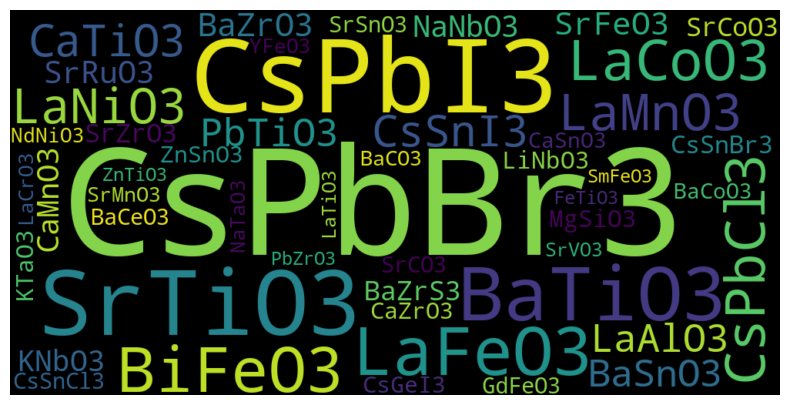

In [18]:
def gerar_nuvem_palavras(dicionario_frequencia, largura=1000, altura=500, cor_fundo='black', interpolacao='bilinear', mostrar_eixos=False, mostrar=True, max_termos=None, colormap='viridis'):
    """
    Gera uma nuvem de palavras a partir de um dicionário de frequência.

    Parâmetros:
    - dicionario_frequencia (dict): Dicionário contendo as frequências das palavras.
    - largura (int): Largura da imagem da nuvem de palavras em pixels. (Padrão: 800)
    - altura (int): Altura da imagem da nuvem de palavras em pixels. (Padrão: 400)
    - cor_fundo (str): Cor de fundo da imagem da nuvem de palavras. (Padrão: 'white')
    - interpolacao (str): Método de interpolação para exibição da imagem da nuvem de palavras. (Padrão: 'bilinear')
    - mostrar_eixos (bool): Indica se os eixos da imagem devem ser exibidos. (Padrão: False)
    - mostrar (bool): Indica se a nuvem de palavras deve ser exibida. Se definido como False, apenas a imagem será retornada. (Padrão: True)
    - max_termos (int or None): Número máximo de termos a serem exibidos na nuvem de palavras. Se None, todos os termos serão exibidos. (Padrão: None)
    - colormap (str): Mapa de cores a ser utilizado na nuvem de palavras. Consulte a documentação do matplotlib para obter uma lista de colormaps disponíveis. (Padrão: 'viridis')

    Retorna:
    - Se mostrar for True, exibe a nuvem de palavras. Caso contrário, retorna a imagem da nuvem de palavras.
    """
    # Limitar o número de termos
    if max_termos is not None:
        dicionario_frequencia = dict(sorted(dicionario_frequencia.items(), key=lambda item: item[1], reverse=True)[:max_termos])

    # Criar a nuvem de palavras
    wordcloud = WordCloud(width=largura, height=altura, background_color=cor_fundo, colormap=colormap).generate_from_frequencies(dicionario_frequencia)

    # Configurar a exibição da nuvem de palavras usando matplotlib
    plt.figure(figsize=(largura / 100, altura / 100))
    plt.imshow(wordcloud, interpolation=interpolacao)
    if not mostrar_eixos:
        plt.axis('off')

    if mostrar:
        # Exibir a nuvem de palavras
        plt.show()
    else:
        # Retorna a imagem da nuvem de palavras
        return wordcloud.to_array()

# Exemplo de uso
# Supondo que você tenha um dicionário chamado dicionario_exemplo
gerar_nuvem_palavras(perovs_reais, max_termos=50, colormap='viridis')